## MTL Trajet: 06 Mode Speed Downtown Patterns (Flag 6)

### Dataset Overview
MTL urban motor-vehicle and cycling trajectories with trip-level speed, downtown-distance, time-period, endpoint, and point-speed information.

The notebook exposes a primary table and a supporting table (`trajectory_points.csv`).

Goal: Based on trajectories of motor vehicles and bikes, investigate differences of these two transportation modes

Role: Urban trajectory analyst


Category: Transport mode, speed, time period, and downtown distance

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectories.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "trajectory_points.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: During peak periods, do some cycling trajectories exceed the speeds of the slower motor-vehicle trajectories?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

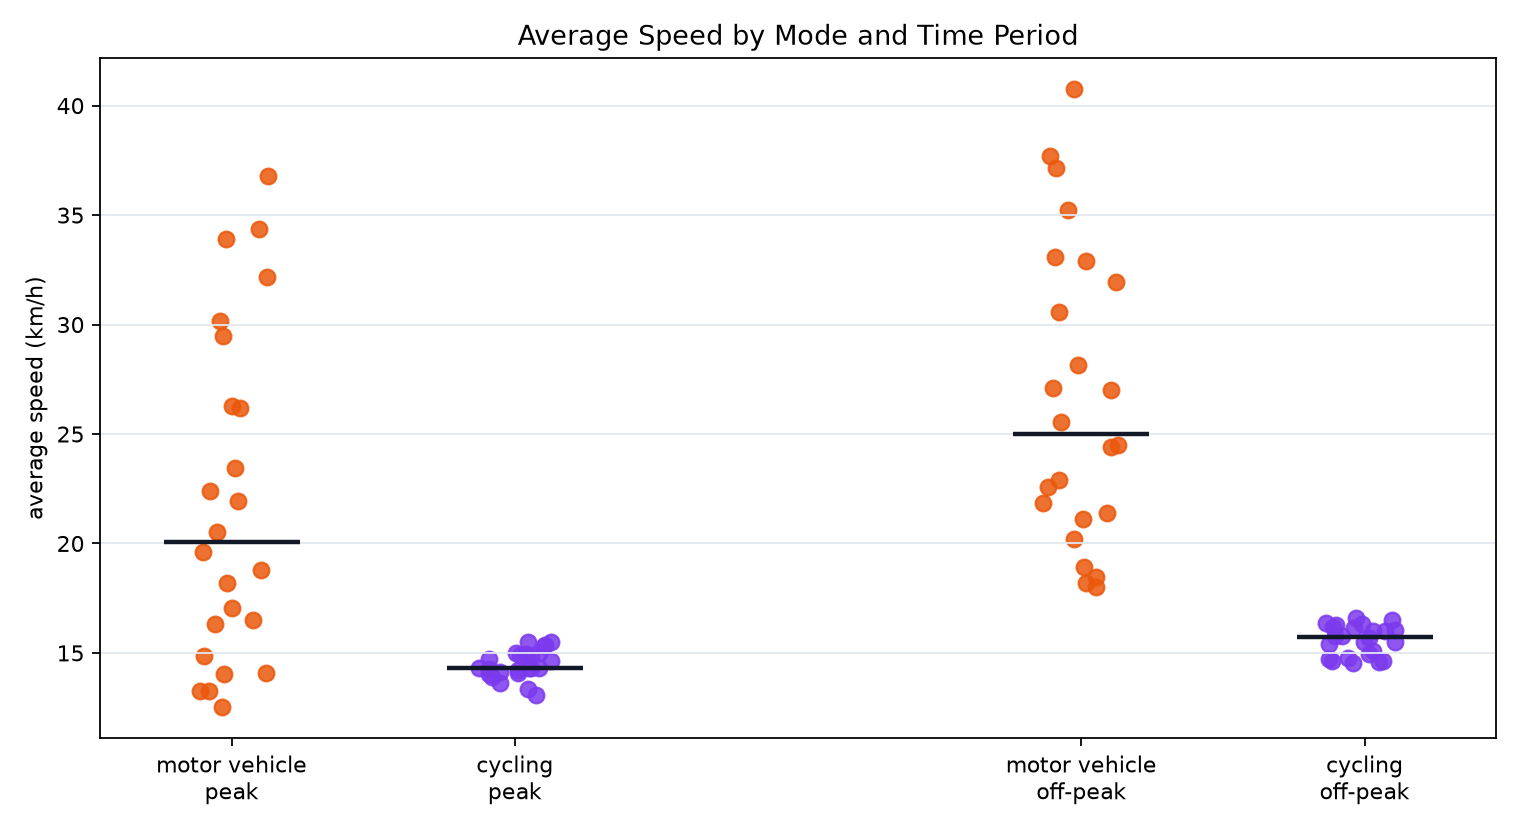

In [ ]:
df.groupby(['time_period','mode_group']).avg_speed_kmh.agg(['min','median','max'])
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/speed_by_mode_time_period.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "mode_speed_time_period",
  "insight": "Although motor vehicles are generally faster, some cycling trajectories outperform slower car trajectories during peak periods.",
  "insight_type": "group_comparison",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Average Speed by Mode and Time Period",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/speed_by_mode_time_period.png"
  },
  "question": "During peak periods, do some cycling trajectories exceed the speeds of the slower motor-vehicle trajectories?",
  "code": "df.groupby(['time_period','mode_group']).avg_speed_kmh.agg(['min','median','max'])",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "transport_mode",
    "trajectory_timestamp",
    "trajectory_id",
    "point_speed"
  ]
}

### **Question 2**: How does the motor-vehicle versus cycling speed difference change with distance to downtown?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

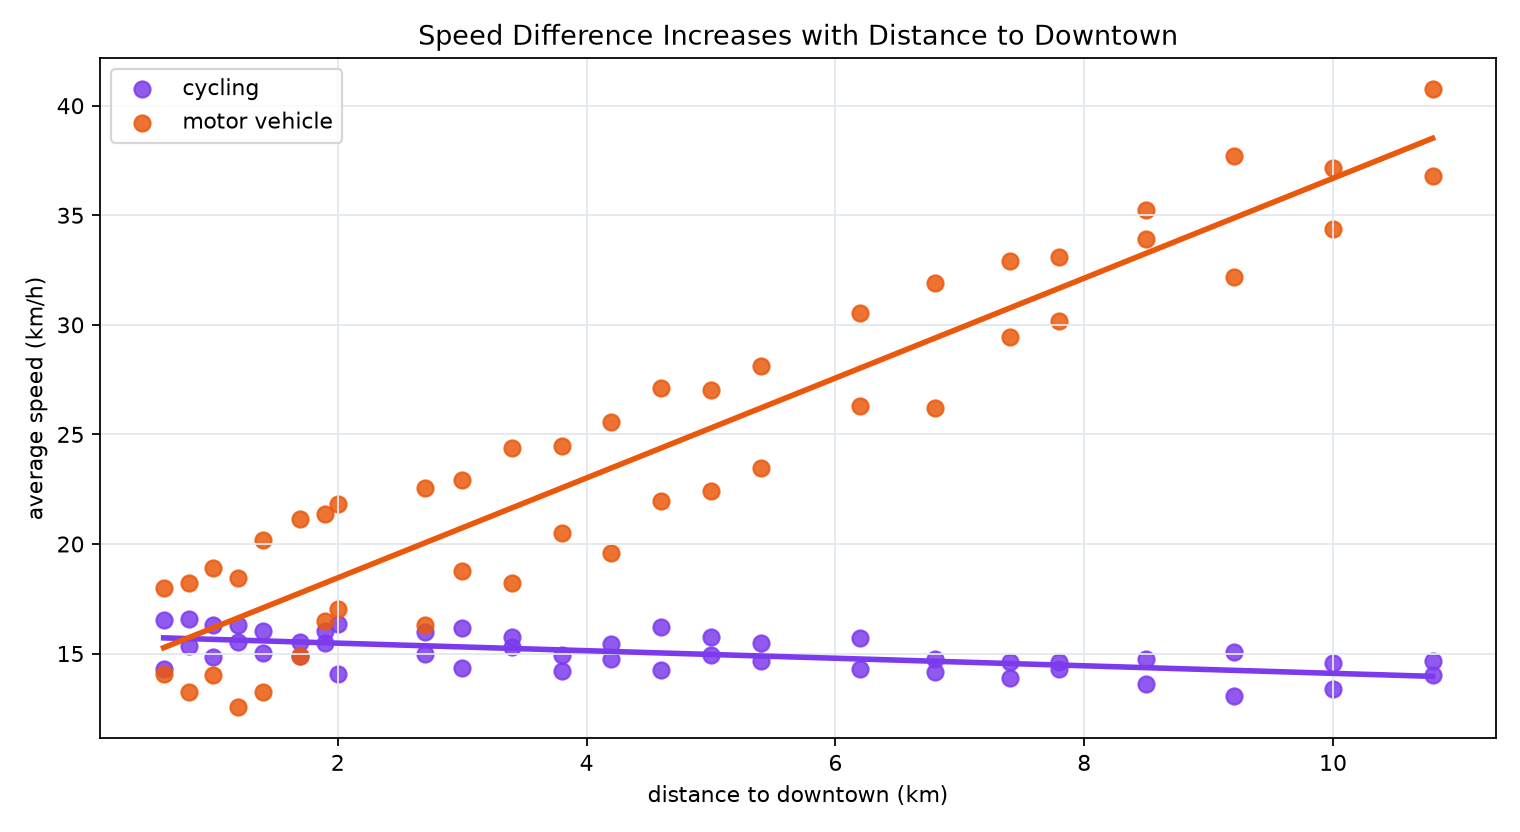

In [ ]:
df.groupby(['distance_to_downtown_band','mode_group']).avg_speed_kmh.median()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/speed_gap_by_downtown_distance.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "mode_speed_downtown_distance",
  "insight": "The speed advantage of motor vehicles becomes larger with the distance to the downtown area",
  "insight_type": "factor_relationship",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Speed Difference by Distance to Downtown",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/speed_gap_by_downtown_distance.png"
  },
  "question": "How does the motor-vehicle versus cycling speed difference change with distance to downtown?",
  "code": "df.groupby(['distance_to_downtown_band','mode_group']).avg_speed_kmh.median()",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "transport_mode",
    "gps_position",
    "downtown_reference",
    "point_speed",
    "trajectory_id"
  ]
}

### **Question 3**: Which mode shows greater within-trajectory point-speed variation across urban trips?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

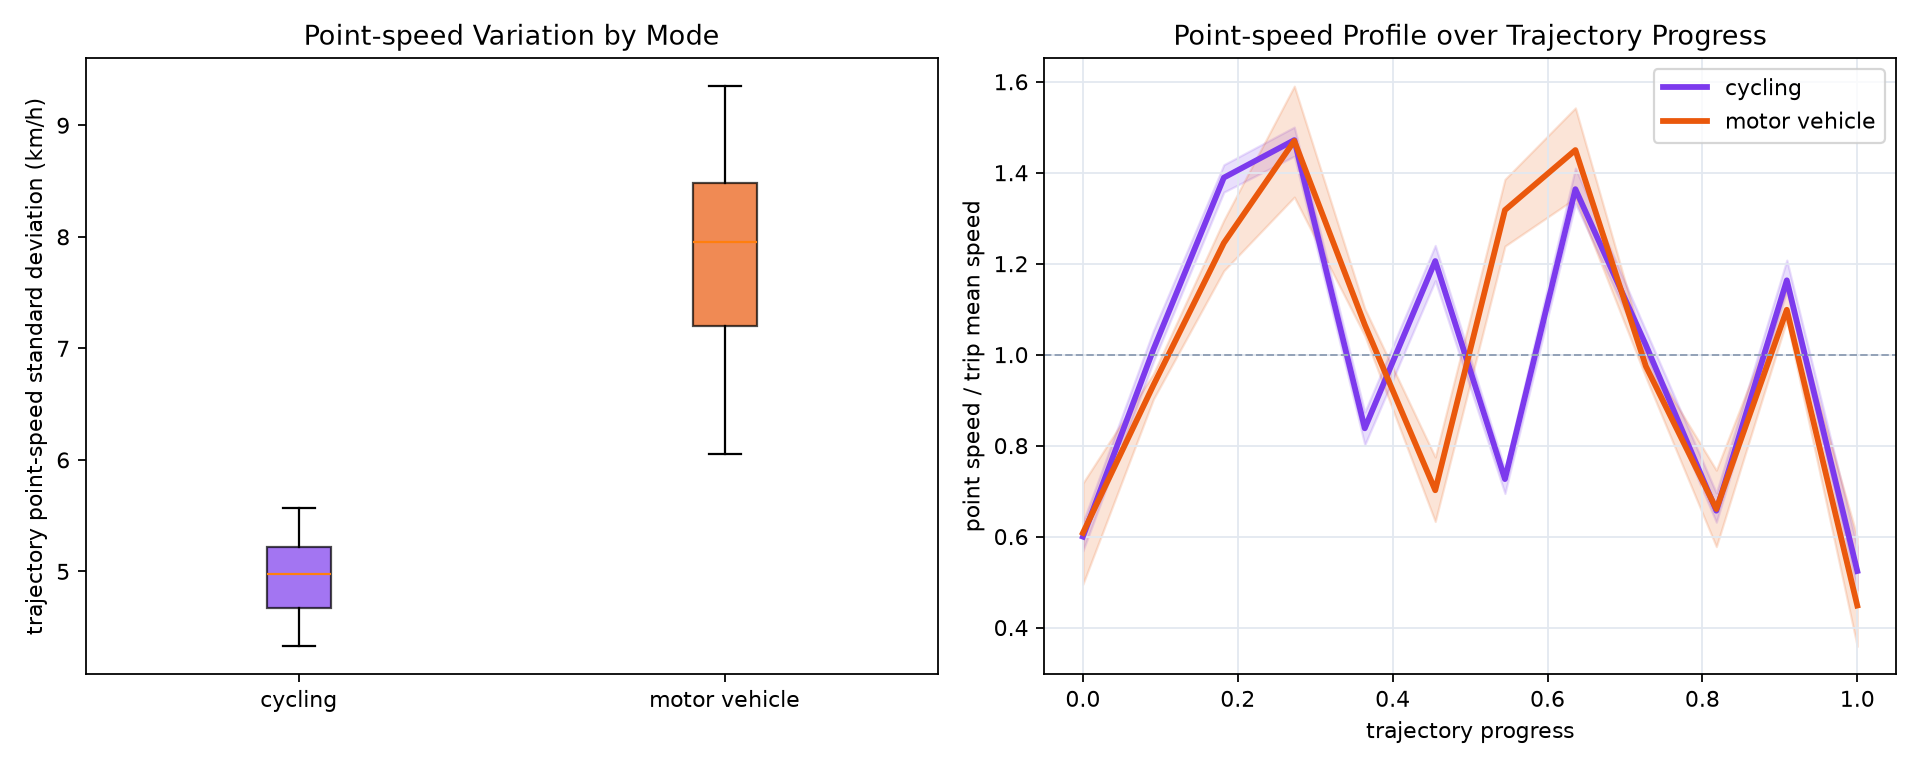

In [ ]:
df.groupby('mode_group').point_speed_std_kmh.agg(['median','mean','max'])
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/point_speed_variation_by_mode.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "mode_point_speed_variation",
  "insight": "Motor vehicle trajectories show larger speed variation than bikes with respect to trajectory progress generally",
  "insight_type": "group_comparison",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Point-speed Variation by Mode",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/point_speed_variation_by_mode.png"
  },
  "question": "Which mode shows greater within-trajectory point-speed variation across urban trips?",
  "code": "df.groupby('mode_group').point_speed_std_kmh.agg(['median','mean','max'])",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "transport_mode",
    "point_speed",
    "trajectory_id"
  ]
}

### Summary of Findings (Flag 6)

Motor-vehicle trajectories are generally faster, but slow peak-period motor trips overlap with some cycling speeds. The motor-vehicle speed advantage grows farther from downtown, while motor-vehicle point speeds vary more within a trip than cycling point speeds.